In [40]:
import os, sys

sys.path.append(os.path.dirname(os.path.dirname(os.path.abspath("__file__"))))
from nbafuns import *

img_DIR_P = "../data/images/players/"
fig_DIR = "../figs/playoffs/"

In [68]:
yr = 2015
seasons = range(yr,yr+5)
df1 = get_box("P","Base","True",seasons,False)
df2 = get_box("P","Base","True",seasons,True)

In [69]:
df1["min_t"] = df1["gp"]*df1["min"]
df1_1 = df1[["player_id","player_name","min_t"]]
df1_1 = df1_1.groupby(["player_id","player_name"])["min_t"].sum().reset_index()
df2["min_t"] = df2["gp"]*df2["min"]
df2_1 = df2[["player_id","min_t"]]
df2_1 = df2_1.groupby(["player_id"])["min_t"].sum().reset_index()
df3 = pd.merge(df1_1,df2_1,on=["player_id"])

In [70]:
df3["min"] = df3["min_t_x"]+df3["min_t_y"]
df3["min"] = df3["min"].round(1)
df4 = df3.sort_values("min",ascending=False).reset_index(drop=True)
df4 = df4[["player_id","player_name","min"]]
df4["player_id"] = df4["player_id"].astype(str)
df4 = df4.reset_index()
df4["index"]+=1
df4 = df4.head(15)

GT(_tbl_data=    index player_id            player_name      min
0       1    201935           James Harden  16066.5
1       2      2544           LeBron James  16031.4
2       3    203468            CJ McCollum  14989.5
3       4    203081         Damian Lillard  14899.8
4       5    201942          DeMar DeRozan  14861.5
5       6    201566      Russell Westbrook  14708.1
6       7    200768             Kyle Lowry  14662.1
7       8    202331            Paul George  14045.3
8       9    203507  Giannis Antetokounmpo  14016.0
9      10    203110         Draymond Green  13999.0
10     11    200782            P.J. Tucker  13991.4
11     12    202689           Kemba Walker  13851.3
12     13    202699          Tobias Harris  13808.4
13     14    202691          Klay Thompson  13529.3
14     15    203952         Andrew Wiggins  13432.1, _body=<great_tables._gt_data.Body object at 0x0000021909DECD00>, _boxhead=Boxhead([ColInfo(var='index', type=<ColInfoTypeEnum.default: 1>, column_label='#', column_align='right', column_width=None), ColInfo(var='player_id', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='right', column_width=None), ColInfo(var='player_name', type=<ColInfoTypeEnum.default: 1>, column_label='Player', column_align='left', column_width=None), ColInfo(var='min', type=<ColInfoTypeEnum.default: 1>, column_label='Minutes', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x0000021909D392D0>, _spanners=Spanners([]), _heading=Heading(title='Most Minutes Played RS + Playoffs: 2021-2025', subtitle=None, preheader=None), _stubhead=None, _source_notes=['@sradjoker | source: nba.com/stats'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x0000021909DEE200>, _formats=[<great_tables._gt_data.FormatInfo object at 0x0000021909DEF2E0>], _substitutions=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='snow'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value=12), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=T
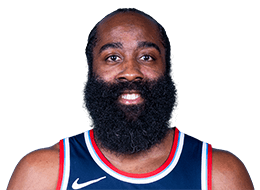
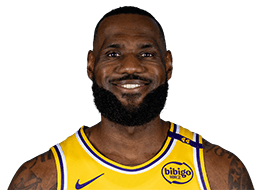
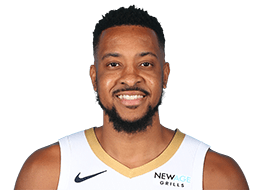
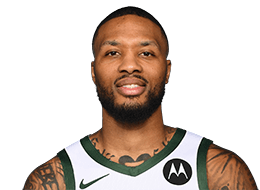
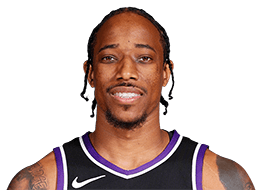
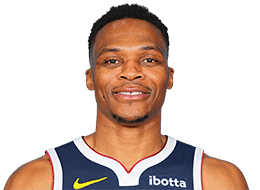
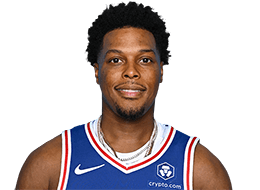
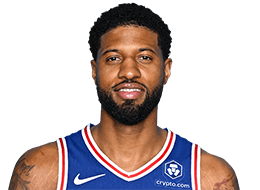
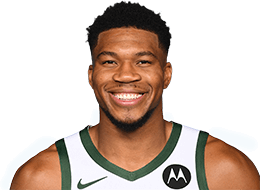
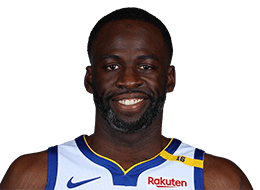
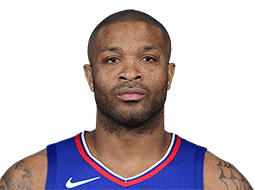
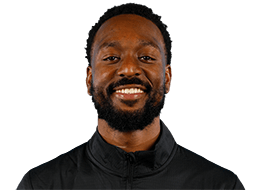
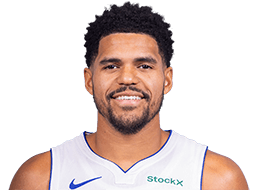
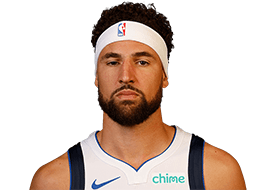
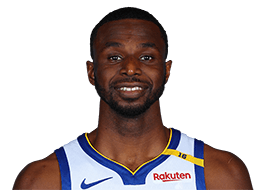

In [71]:
t = (
    GT(df4)
    .tab_header(
        title="Most Minutes Played RS + Playoffs: 2021-2025"
    )
    .tab_source_note("@sradjoker | source: nba.com/stats")
    .cols_label(
        index="#",
        player_id="",
        player_name="Player",
        min="Minutes"
    )
    .fmt_image(
        columns="player_id",
        path=img_DIR_P,
        file_pattern="{}.png",
        height = 40,
    )
    .tab_options(
        heading_title_font_size="150%",
        heading_subtitle_font_size="150%",
        # table_background_color="ghostwhite",
        table_background_color="snow",
        column_labels_font_size="105%",
        column_labels_font_weight='bold',
        row_group_font_weight='bold',
        row_group_background_color="#E5E1D8",
        table_font_size=12,
        # table_font_names="Consolas", 
        data_row_padding = "3px",
    )
)
# t.save(fig_DIR + f"most_minutes_played.png",scale=3,web_driver="firefox")
t